# NoFlyZone: Passenger Satisfaction from Airport Surveys
### CIS4930 - Introduction to Machine Learning | Term project

**Research question:** How well can passenger context and service ratings classify `liked` for unseen survey profiles?

This is a retrospective classification study. The source defines `liked=1` as overall satisfaction of 4 or 5, and `liked=0` for lower ratings. That overall-satisfaction answer is excluded from the predictors. Service ratings come from the same survey, so the model describes associations after the experience.

## 1. Data and source

[Real Airline Passenger Satisfaction Dataset, Rustam32 on Kaggle](https://www.kaggle.com/datasets/rustam32/real-airline-passenger-satisfaction-dataset), based on [Brazil Ministry of Transport airport passenger surveys](https://dados.transportes.gov.br/dataset/pesquisa-de-satisfacao-do-passageiro-em-aeroportos).

The data card reports keeping 28,757 negative responses and randomly selecting the same number of positive responses. This balances the file by undersampling the positive class. Time fields are in seconds; `*_is_applicable` flags indicate whether a question applies (1) or does not apply (0). The listed license is MIT.

The upstream build script, collection years, airport coverage, and original positive prevalence have not been independently audited. Counts and experiment results below come from the supplied CSV; its SHA-256 identifies the input.

Use the `noflyzone` Conda environment and run the notebook from this folder. `project_support.py` supplies the feature transformers and grouped stacking estimator.

In [1]:
from pathlib import Path
import os, sys, json, time, hashlib, platform
if os.name == 'nt' and (Path(sys.prefix) / 'Library/bin').exists():
    _conda_dll = os.add_dll_directory(str(Path(sys.prefix) / 'Library/bin'))
    os.environ['PATH'] = str(Path(sys.prefix) / 'Library/bin') + os.pathsep + os.environ['PATH']
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('TF_ENABLE_ONEDNN_OPTS', '0')
os.environ.setdefault('OMP_NUM_THREADS', '4')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_selection import VarianceThreshold, SelectPercentile, f_classif
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay, classification_report,
    brier_score_loss, log_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
import sklearn, joblib
_joblib_backend = joblib.parallel_backend('threading')
_joblib_backend.__enter__()  # Avoid Windows process/memmap cleanup issues; estimator seeds are unchanged.
from project_support import SurveyFeatures, QuantileClipper, GroupedStackingClassifier

SEED = 42
np.random.seed(SEED)
threadpool_limits(limits=4)
ROOT = Path.cwd()
assert (ROOT / 'passenger_survey_balanced.csv').exists(), 'Run from the MLProject folder.'
OUT = ROOT / 'outputs'
for folder in ['figures', 'tables', 'models']:
    (OUT / folder).mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook', palette=['#147D92', '#DA8046'])
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 180, 'axes.spines.top': False, 'axes.spines.right': False})
def figure(name):
    plt.tight_layout()
    plt.savefig(OUT / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close('all')
def table(frame, name):
    frame.to_csv(OUT / 'tables' / (name + '.csv'), index=False)
    display(frame)

DATA_PATH = ROOT / 'passenger_survey_balanced.csv'
raw = pd.read_csv(DATA_PATH)
dataset_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert raw.columns.is_unique and raw['liked'].notna().all()
assert set(raw['liked'].unique()) == {0, 1}
display(raw.head())
print('SHA-256:', dataset_hash)
print('Python:', platform.python_version(), '| scikit-learn:', sklearn.__version__)

,process,month,flight_type,connection,ticket_purchased_by,ticket_purchase_channel,transport_to_airport,has_disability,uses_assistive_device,requested_special_assistance,...,restrooms_is_applicable,restroom_quantity_is_applicable,restroom_cleanliness_is_applicable,restroom_maintenance_is_applicable,baggage_claim_process_is_applicable,baggage_carousel_identification_ease_is_applicable,baggage_claim_time_is_applicable,baggage_integrity_is_applicable,arrival_lead_time_is_applicable,connection_wait_time_is_applicable
0,Boarding,October,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride from someone,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0
1,Boarding,March,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride-hailing app,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0
2,Disembarkation,January,Domestic,Not applicable,Not applicable,Not applicable,Not applicable,No,Not applicable,Not applicable,...,0,0,0,0,1,0,0,0,0,0
3,Boarding,August,Domestic,Boarded at the airport,By the passenger,Airline website/app,Ride-hailing app,No,Not applicable,Not applicable,...,1,1,1,1,0,0,0,0,1,0
4,Boarding,February,Domestic,Boarded at the airport,By the passenger,Travel agency/third-party website,Bus,No,Not applicable,Not applicable,...,1,0,0,0,0,0,0,0,1,0


SHA-256: 3cdf9ba9e702bf542ff9a24e9f5b9b571798fd277d778e0f0597cce858657be2
Python: 3.14.6 | scikit-learn: 1.9.0


Loaded **57,514 rows × 145 columns** (144 candidate predictors).

In [2]:
dictionary = pd.DataFrame({'feature': raw.columns, 'dtype': raw.dtypes.astype(str).values,
    'non_null': raw.notna().sum().values, 'missing_pct': raw.isna().mean().values * 100,
    'unique_non_null': raw.nunique().values})
dictionary['role'] = np.where(dictionary.feature.eq('liked'), 'binary target',
    np.where(dictionary.feature.str.endswith('_is_applicable'), 'applicability indicator',
    np.where(dictionary.dtype.eq('object'), 'categorical context', 'numeric survey field')))
dictionary.to_csv(OUT / 'tables/data_dictionary.csv', index=False)
display(dictionary.head(15))
display(raw.describe().T.head(15))
raw.describe(include='all').T.to_csv(OUT / 'tables/descriptive_statistics.csv')

,feature,dtype,non_null,missing_pct,unique_non_null,role
0,process,str,57514,0.000000,2,numeric survey field
1,month,str,57514,0.000000,12,numeric survey field
2,flight_type,str,57514,0.000000,2,numeric survey field
3,connection,str,57514,0.000000,3,numeric survey field
4,ticket_purchased_by,str,57514,0.000000,3,numeric survey field
5,ticket_purchase_channel,str,41374,28.062733,12,numeric survey field
6,transport_to_airport,str,57513,0.001739,16,numeric survey field
7,has_disability,str,57514,0.000000,5,numeric survey field
8,uses_assistive_device,str,55813,2.957541,11,numeric survey field
9,requested_special_assistance,str,56487,1.785652,11,numeric survey field


,count,mean,std,min,25%,50%,75%,max
disembarkation_method_rating,330.0,3.739394,1.171583,1.0,3.0,4.0,5.0,5.0
curbside_dropoff_ease,20958.0,4.131215,0.953496,1.0,4.0,4.0,5.0,5.0
transport_options_to_airport,16829.0,3.807832,1.055072,1.0,3.0,4.0,5.0,5.0
checkin_process,8489.0,4.075745,1.122362,1.0,4.0,4.0,5.0,5.0
checkin_queue_wait_time,1843.0,2.670646,1.305023,1.0,1.5,3.0,4.0,5.0
checkin_queue_organization,1822.0,2.875412,1.276820,1.0,2.0,3.0,4.0,5.0
self_service_kiosk_quantity,340.0,3.220588,1.142445,1.0,2.0,3.0,4.0,5.0
checkin_counter_quantity,1582.0,2.665613,1.239787,1.0,2.0,3.0,4.0,5.0
staff_courtesy,1587.0,3.615627,1.196762,1.0,3.0,4.0,4.0,5.0
checkin_service_time,1587.0,3.293636,1.251271,1.0,2.0,4.0,4.0,5.0


## 2. Define the machine learning problem

- **Task:** supervised binary classification; each row is a survey record, and `liked` is the label. Regression would impose an inappropriate continuous target; clustering would answer a different question.
- **Use case:** retrospectively identify survey patterns associated with the positive/negative label, potentially informing service follow-up. A false positive labels a negative experience as positive; a false negative flags a positive experience for review.
- **Primary selection metric:** macro F1, which gives equal importance to both classes. Also report accuracy, balanced accuracy, positive-class precision/recall/F1, ROC-AUC, and average precision. Ranking scores and classification scores answer different questions.
- **Unit of generalization:** an unseen observed feature profile in this dataset. There is no reliable passenger, airport, or timestamp identifier, so generalization to new airports or future years is not established.
- **Fairness:** exclude explicit demographic fields from predictive inputs, retain them for auditing, and examine subgroup support and error rates. Removing these variables does not remove correlated proxies or establish fairness.

## 3. Data integrity and exploratory analysis

We inspect whole-file schema, label counts, and duplicates to define the evaluation population. Feature/label relationship plots and modeling choices use the training partition only. Exact repeated rows are removed because their origin is unknown; identical predictors with conflicting labels are retained and assigned to the same split. This changes the target population to unique survey records and does not recover the original population prevalence.

,split,rows,positive_rate,unique_profiles
0,train,26269,0.447295,24676
1,validation,8756,0.447236,8248
2,test,8756,0.447236,8278


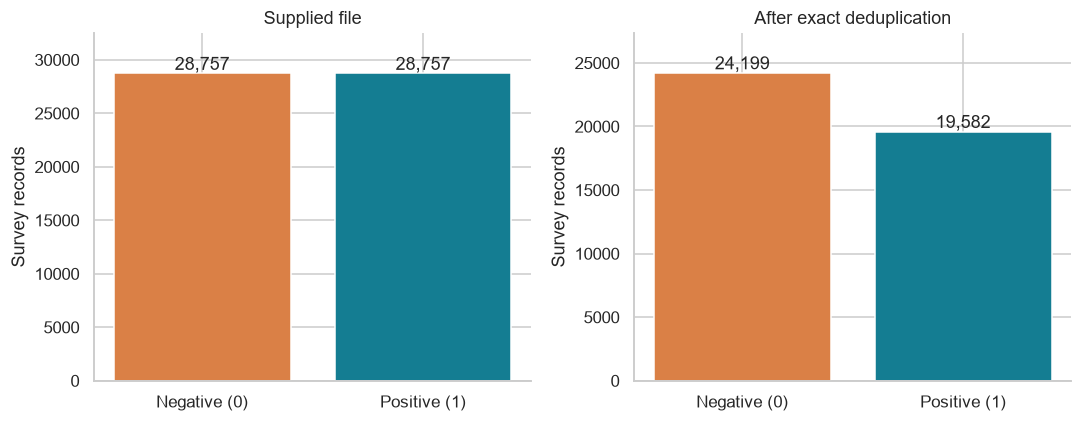

In [3]:
duplicate_count = int(raw.duplicated().sum())
data = raw.drop_duplicates().copy()
data.insert(0, 'source_row', data.index)
data.reset_index(drop=True, inplace=True)
TARGET = 'liked'
SENSITIVE = ['gender', 'age_group', 'nationality', 'education', 'household_income',
             'has_disability', 'uses_assistive_device', 'requested_special_assistance']
X = data.drop(columns=[TARGET, 'source_row'] + SENSITIVE)
y = data[TARGET].astype(int)
# Group by model inputs, so profiles made identical by demographic exclusion stay together.
groups = pd.util.hash_pandas_object(X, index=False).astype(str)
conflicts = pd.DataFrame({'group': groups, 'y': y}).groupby('group').y.nunique()
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(outer.split(X, y, groups))
inner = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
a, b = next(inner.split(X.iloc[dev_idx], y.iloc[dev_idx], groups.iloc[dev_idx]))
train_idx, val_idx = dev_idx[a], dev_idx[b]
X_train, X_val, X_test = [X.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
y_train, y_val, y_test = [y.iloc[ix].copy() for ix in [train_idx, val_idx, test_idx]]
g_train, g_val, g_test = [groups.iloc[ix] for ix in [train_idx, val_idx, test_idx]]
assert not (set(g_train) & set(g_val) or set(g_train) & set(g_test) or set(g_val) & set(g_test))
assert len(train_idx) + len(val_idx) + len(test_idx) == len(data)
split_manifest = data[['source_row', 'liked']].copy()
split_manifest['profile_group'] = groups
split_manifest['split'] = ''
for label, ix in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]:
    split_manifest.loc[ix, 'split'] = label
split_manifest.to_csv(OUT / 'tables/split_manifest.csv', index=False)
split_summary = pd.DataFrame([{'split': n, 'rows': len(ix), 'positive_rate': y.iloc[ix].mean(),
    'unique_profiles': groups.iloc[ix].nunique()} for n, ix in [('train', train_idx), ('validation', val_idx), ('test', test_idx)]])
table(split_summary, 'split_summary')

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, frame, title in zip(axes, [raw, data], ['Supplied file', 'After exact deduplication']):
    counts = frame.liked.value_counts().sort_index()
    ax.bar(['Negative (0)', 'Positive (1)'], counts, color=['#DA8046','#147D92'])
    ax.set(title=title, ylabel='Survey records')
    ax.set_ylim(0, counts.max() * 1.13)
    for i, v in enumerate(counts): ax.text(i, v + 300, f'{v:,}', ha='center')
figure('01_class_balance')

**13,733 exact duplicates removed**; **43,781 records retained**. 881 modeled feature profiles have conflicting labels. The retained positive share is **44.7%**. No modeled profile overlaps splits.

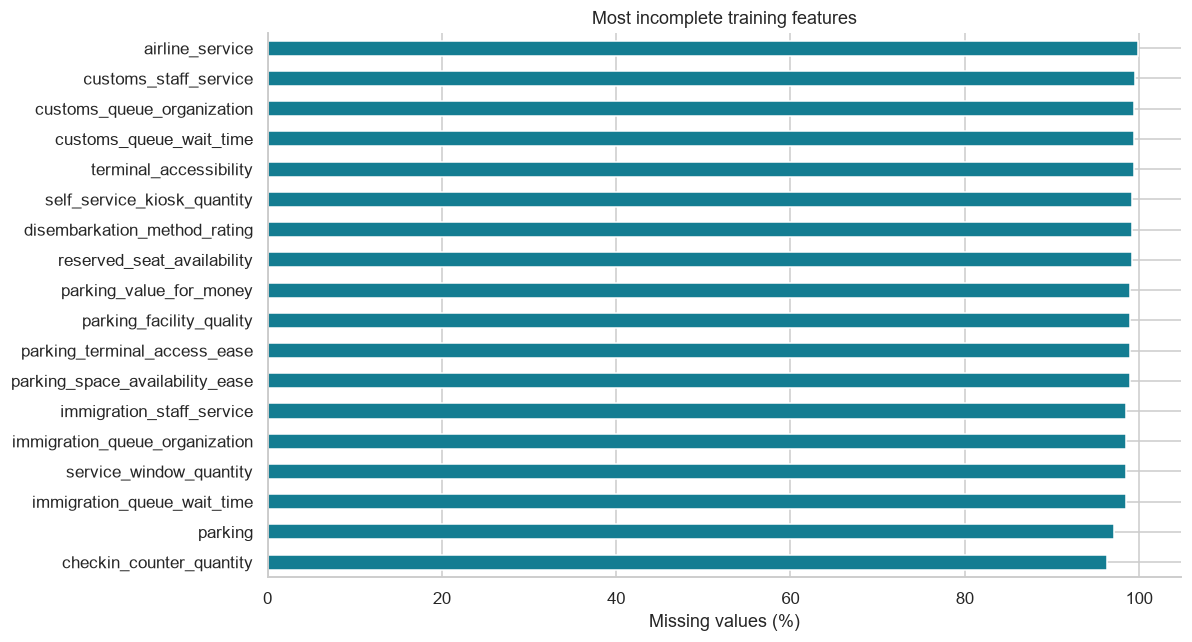

,feature,missing_fraction
0,airline_service,0.998553
1,customs_staff_service,0.994785
2,customs_queue_organization,0.994594
3,customs_queue_wait_time,0.994518
4,terminal_accessibility,0.993681
...,...,...
131,baggage_carousel_identification_ease_is_applic...,0.000000
132,baggage_claim_time_is_applicable,0.000000
133,baggage_integrity_is_applicable,0.000000
134,arrival_lead_time_is_applicable,0.000000


,feature,observed,minimum,maximum,invalid_outside_1_5
0,disembarkation_method_rating,210,1.0,5.0,0
1,curbside_dropoff_ease,12621,1.0,5.0,0
2,transport_options_to_airport,10142,1.0,5.0,0
3,checkin_process,5104,1.0,5.0,0
4,checkin_queue_wait_time,1118,1.0,5.0,0
5,checkin_queue_organization,1106,1.0,5.0,0
6,self_service_kiosk_quantity,208,1.0,5.0,0
7,checkin_counter_quantity,961,1.0,5.0,0
8,staff_courtesy,966,1.0,5.0,0
9,checkin_service_time,964,1.0,5.0,0


,feature,applicable_but_missing,not_applicable_but_observed
28,retail_outlets,16399,0
46,airport_internet,15061,0
3,checkin_process,14794,0
24,food_beverage_outlets,10732,0
2,transport_options_to_airport,9756,0
10,ticket_purchase_process,9689,0
1,curbside_dropoff_ease,7277,0
12,security_screening_process,6525,0
49,restrooms,6297,0
45,power_outlet_availability,5522,0


In [4]:
train_data = data.iloc[train_idx]
missing = X_train.isna().mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(11, 6))
missing.head(18).sort_values().mul(100).plot.barh(ax=ax, color='#147D92')
ax.set(xlabel='Missing values (%)', title='Most incomplete training features')
figure('02_missingness')
table(pd.DataFrame({'feature':missing.index, 'missing_fraction':missing.values}), 'training_missingness')

TIME_COLS = ['arrival_lead_time', 'connection_wait_time']
RATINGS = [c for c in X.select_dtypes('number') if c not in TIME_COLS and not c.endswith('_is_applicable')]
FLAGS = [c for c in X if c.endswith('_is_applicable')]
rating_audit = pd.DataFrame([{'feature':c, 'observed':int(X_train[c].notna().sum()),
    'minimum':X_train[c].min(), 'maximum':X_train[c].max(),
    'invalid_outside_1_5':int((X_train[c].notna() & ~X_train[c].between(1,5)).sum())} for c in RATINGS])
table(rating_audit.head(10), 'rating_range_preview')
rating_audit.to_csv(OUT / 'tables/rating_range_audit.csv', index=False)
assert rating_audit.invalid_outside_1_5.sum() == 0
applicability_audit = []
for flag in FLAGS:
    base = flag.removesuffix('_is_applicable')
    applicability_audit.append({'feature':base,
        'applicable_but_missing':int(((X_train[flag]==1) & X_train[base].isna()).sum()),
        'not_applicable_but_observed':int(((X_train[flag]==0) & X_train[base].notna()).sum())})
table(pd.DataFrame(applicability_audit).sort_values('applicable_but_missing', ascending=False).head(10), 'applicability_preview')
pd.DataFrame(applicability_audit).to_csv(OUT / 'tables/applicability_audit.csv', index=False)

**Missing is not the same as dissatisfied.** Many questions only apply to one journey stage or a particular service. We retain source applicability flags, add missingness indicators, and median-impute ratings inside each training fold. Literal “Not applicable” categorical answers remain a distinct category; actual missing categorical values use a separate token.

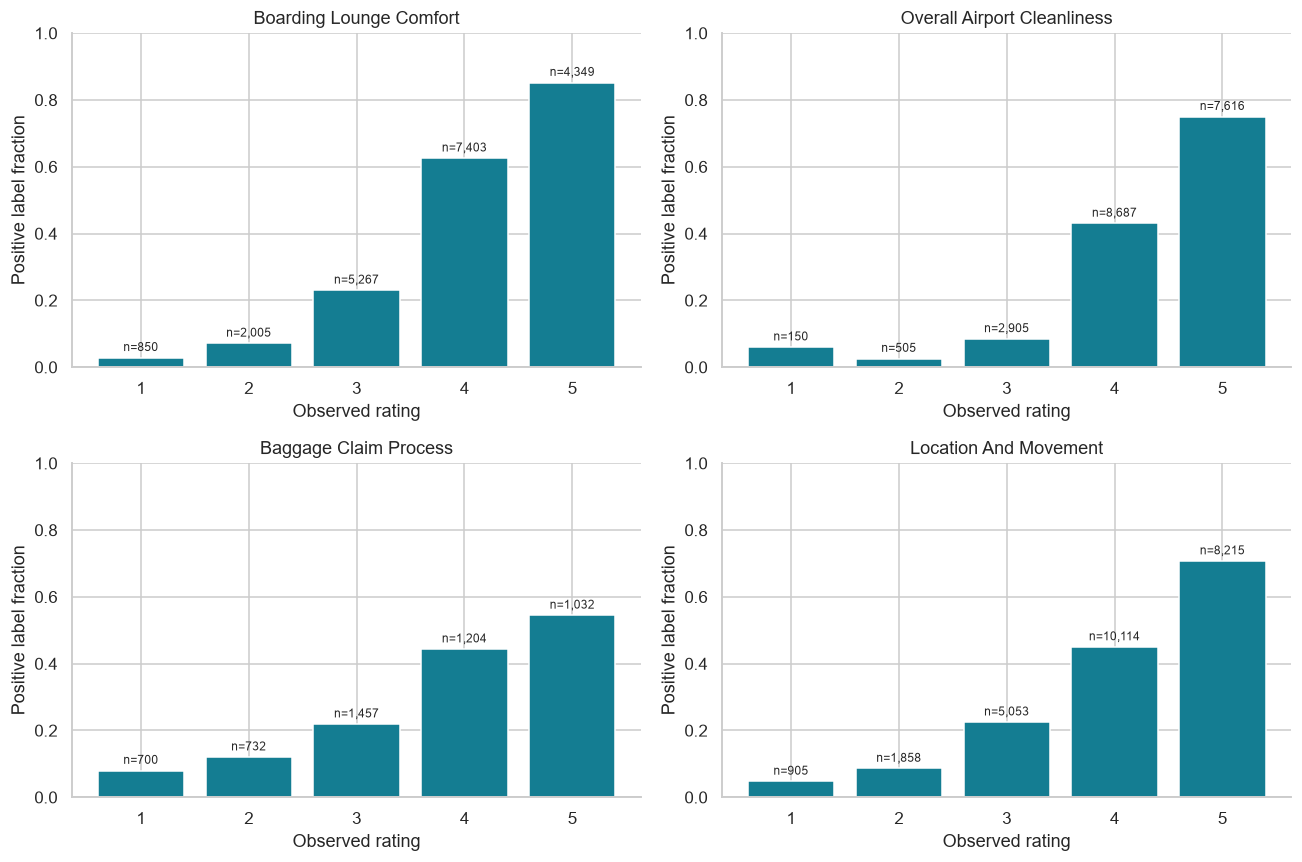

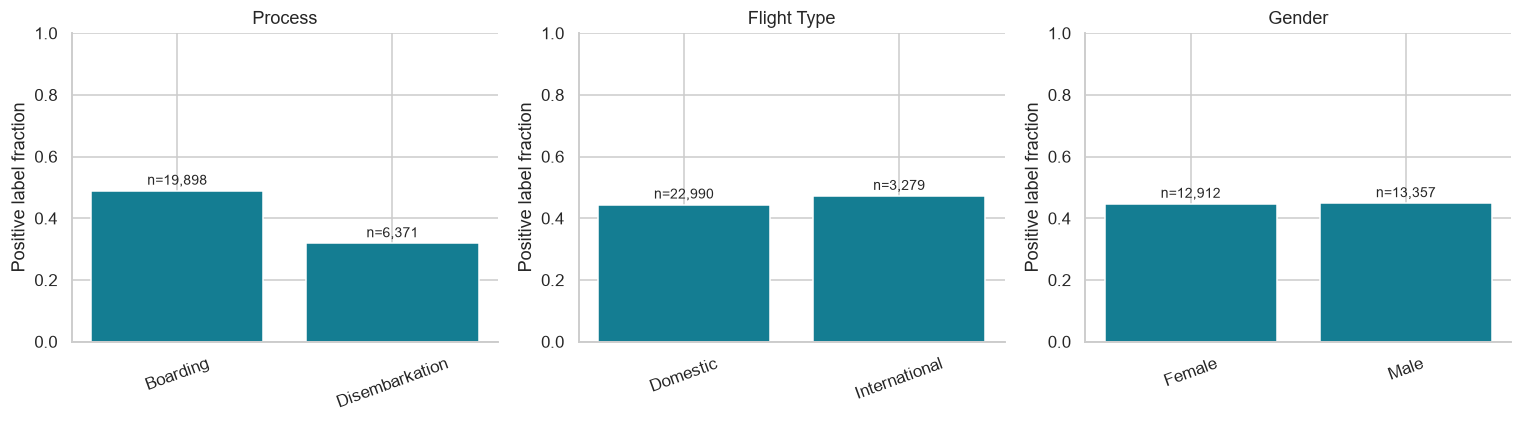

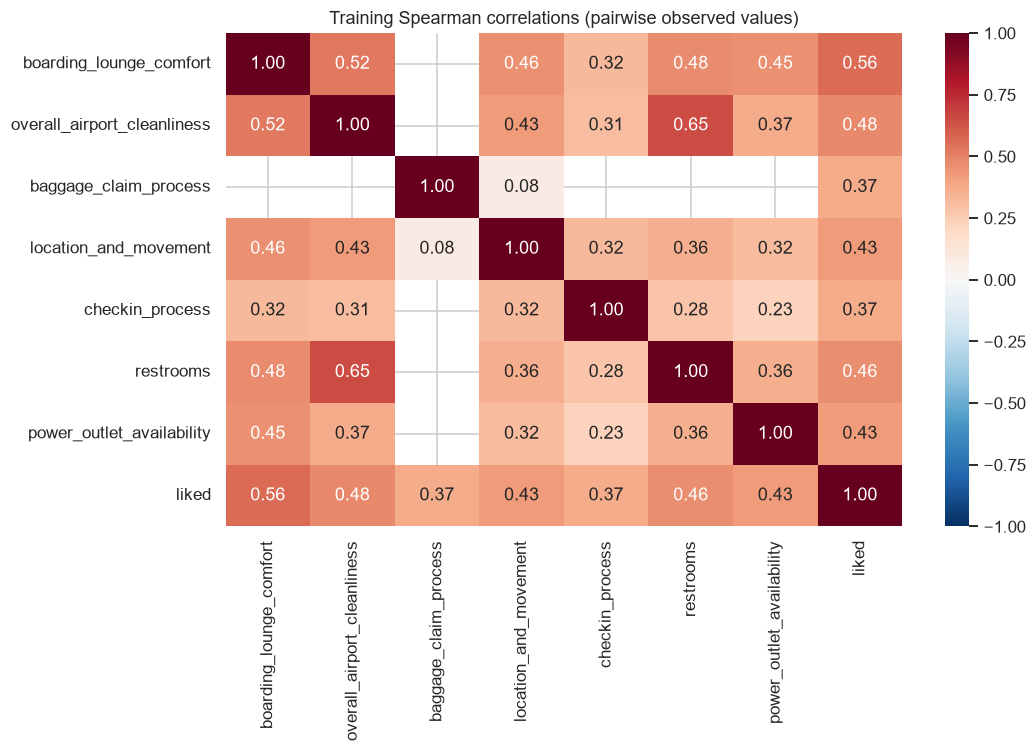

In [5]:
selected_ratings = ['boarding_lounge_comfort','overall_airport_cleanliness','baggage_claim_process','location_and_movement']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, c in zip(axes.flat, selected_ratings):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Observed rating', ylabel='Positive label fraction', ylim=(0,1))
    for _, r in tmp.iterrows(): ax.text(r[c], r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=8)
figure('03_ratings_and_label')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, c in zip(axes, ['process','flight_type','gender']):
    tmp = train_data.groupby(c).liked.agg(['mean','count']).reset_index()
    ax.bar(tmp[c], tmp['mean'], color='#147D92')
    ax.set(title=c.replace('_',' ').title(), ylabel='Positive label fraction', ylim=(0,1))
    ax.tick_params(axis='x', labelrotation=20)
    for j, r in tmp.iterrows(): ax.text(j, r['mean'] + .02, f"n={int(r['count']):,}", ha='center', fontsize=9)
figure('04_context_and_label')

corr_columns = selected_ratings + ['checkin_process','restrooms','power_outlet_availability','liked']
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(train_data[corr_columns].corr(method='spearman', min_periods=100), annot=True,
    fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title('Training Spearman correlations (pairwise observed values)')
figure('05_correlations')

Higher recorded service ratings tend to accompany a positive label in these training plots. Each bar uses only respondents with an observed rating; sample sizes differ. Pairwise correlations can reflect different respondent subsets and do not establish cause. The source defines `liked` from a separate overall-satisfaction answer that is absent from the predictors; remaining service ratings are contemporaneous self-reports, so shared response tendencies remain possible.

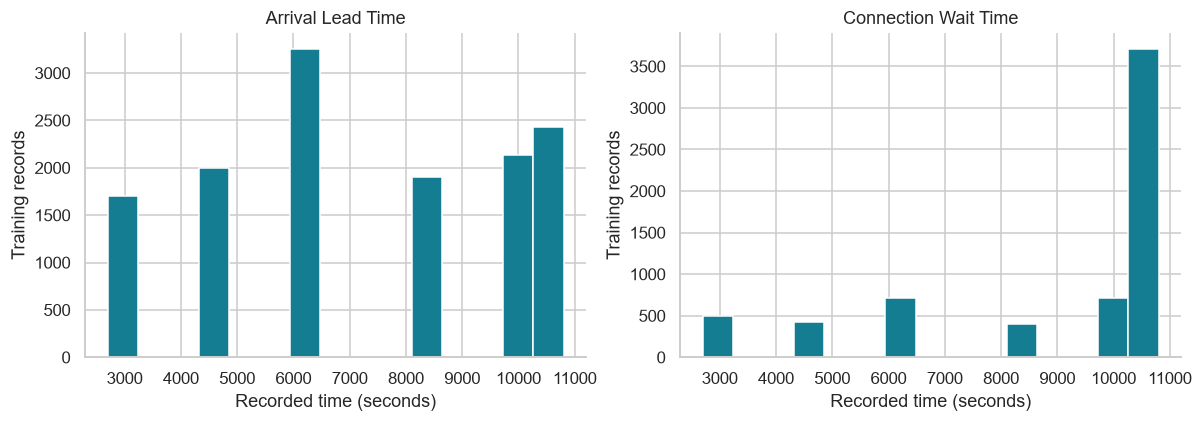

,feature,q1,q3,iqr,outside_iqr,q01,q99
0,arrival_lead_time,4500.0,9900.0,5400.0,0,2700.0,10800.0
1,connection_wait_time,6300.0,10800.0,4500.0,0,2700.0,10800.0


In [6]:
outliers=[]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, c in zip(axes, TIME_COLS):
    values=X_train[c].dropna(); q1,q3=values.quantile([.25,.75]); iqr=q3-q1
    outliers.append({'feature':c,'q1':q1,'q3':q3,'iqr':iqr,
        'outside_iqr':int(((values<q1-1.5*iqr)|(values>q3+1.5*iqr)).sum()),
        'q01':values.quantile(.01),'q99':values.quantile(.99)})
    ax.hist(values,bins=15,color='#147D92')
    ax.set(title=c.replace('_',' ').title(), xlabel='Recorded time (seconds)', ylabel='Training records')
figure('06_time_distributions')
table(pd.DataFrame(outliers),'outlier_audit')

The source documents these time fields in seconds. They have a small number of distinct coded values; we retain their original units. Training-fitted 1st/99th-percentile clipping is applied only to these fields. The audit may show that it changes no values. Valid 1–5 ordinal ratings and binary flags are never winsorized; rare valid answers are preserved.

## 4. Project plan and experimental protocol

1. Preserve the raw file, audit schema/duplicates, define binary target and eligible predictors.
2. Deduplicate exact rows; split approximately 60% training / 20% validation / 20% test with stratification and profile groups. The same partitions are used for every model.
3. Fit feature engineering, imputation, one-hot encoding, scaling, and constant removal inside pipelines. No global fitted preprocessing.
4. Compare a majority baseline, logistic regression, decision tree, KNN, RBF SVM, Gaussian naive Bayes, random forest, bagging, AdaBoost, histogram gradient boosting, group-aware stacking, and a Keras dense neural network.
5. Run three-fold group CV for classical benchmarks on a fixed training-only subset (roughly 12,000 rows) to bound kernel-SVM runtime. Fit final benchmark candidates on the entire training partition. CV and full-training scores have different sample sizes and are labeled accordingly.
6. Tune hyperparameters and feature selection with group-aware CV; compare feature/context ablations on validation. Use **validation macro F1 at the default decision rule** to lock the winning candidate; optionally set its probability threshold on validation.
7. Open the test set only after selection is locked. Report all fixed candidates for transparency, but never change the selection based on test rankings. Add group-bootstrap uncertainty, learning curves, validation permutation importance, and subgroup audits.

**Imbalance:** the original file is balanced, while deduplication produces mild imbalance. Do not apply SMOTE or oversampling before splitting. Stratification, macro F1, balanced accuracy, and a class-weighted logistic-regression tuning option address the issue without creating synthetic survey answers.

**Why these models?** Logistic regression is an interpretable linear baseline; trees model interactions; KNN is distance-based; RBF SVM learns nonlinear boundaries; naive Bayes supplies a simple generative comparison. Bagging/random forests reduce tree variance, boosting combines sequential weak learners, stacking combines out-of-fold predictions, and a dense network learns nonlinear tabular representations. CNNs/RNNs and text vectorization are inappropriate because this CSV contains neither images, sequences, nor free-text responses.

## 5. Data preparation and feature engineering

Predictors already have descriptive snake_case names. `liked` and the audit-only source row number are excluded. Eight demographic/assistance fields are excluded from the main model. Remaining survey responses may still proxy sensitive attributes.

Row-local engineered features are the mean observed service rating, number of observed ratings, and fraction of observed ratings at 1–2. These may capture both sentiment and questionnaire routing; we test removal of engineered aggregates and a context-only model later. No label information enters their calculation.

Numeric values are median-imputed with missing indicators, then standardized. Categorical values are explicitly imputed and one-hot encoded with rare training categories pooled; unseen categories are safely handled. Constant encoded columns are removed. Scaling is essential for KNN/SVM/logistic regression/neural networks and harmless for the tree splits used here.

In [7]:
def make_pipeline(model, columns=None, engineered=True):
    cols = list(X_train.columns if columns is None else columns)
    rating_cols = tuple(c for c in RATINGS if c in cols)
    times = [c for c in TIME_COLS if c in cols]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(X_train[c]) and c not in times]
    cats = [c for c in cols if c not in num + times]
    if engineered and rating_cols:
        num += ['rating_mean','rating_count','low_rating_fraction']
    numeric = Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                        ('scale', StandardScaler())])
    timed = Pipeline([('clip', QuantileClipper()), ('impute', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                      ('scale', StandardScaler())])
    categorical = Pipeline([('impute', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
        ('encode', OneHotEncoder(handle_unknown='ignore', min_frequency=20, sparse_output=False))])
    preprocess = ColumnTransformer([('numeric', numeric, num), ('time', timed, times), ('categorical', categorical, cats)], remainder='drop')
    return Pipeline([('features', SurveyFeatures(rating_cols, enabled=bool(engineered and rating_cols))),
        ('preprocess', preprocess), ('constant_filter', VarianceThreshold()), ('model', model)])

prep_demo = make_pipeline(LogisticRegression(max_iter=1500, random_state=SEED))
prep_demo.fit(X_train, y_train)
transformed = prep_demo[:-1].transform(X_val)
assert np.isfinite(transformed).all()
print('Encoded nonconstant features:', transformed.shape[1])
print('Median imputer, encoder, clipping bounds, and scaler fitted on training only.')

Encoded nonconstant features: 279
Median imputer, encoder, clipping bounds, and scaler fitted on training only.


## 6. Model building and cross-validation

Default predictions use each estimator's `predict`; probability models normally threshold at 0.5. The SVM uses its signed margin directly for ROC-AUC and average precision, avoiding an ungrouped internal probability-calibration split. Probability calibration metrics will only be used for models that supply probabilities.

In [ ]:
def metrics(y_true, prediction, score):
    return {'accuracy':accuracy_score(y_true,prediction),
        'balanced_accuracy':balanced_accuracy_score(y_true,prediction),
        'precision':precision_score(y_true,prediction,zero_division=0),
        'recall':recall_score(y_true,prediction,zero_division=0),
        'f1':f1_score(y_true,prediction,zero_division=0),
        'macro_f1':f1_score(y_true,prediction,average='macro',zero_division=0),
        'roc_auc':roc_auc_score(y_true,score), 'average_precision':average_precision_score(y_true,score)}
def model_score(model, frame):
    return model.predict_proba(frame)[:,1] if hasattr(model,'predict_proba') else model.decision_function(frame)

specs = {
    'Majority baseline':DummyClassifier(strategy='most_frequent'),
    'Logistic regression':LogisticRegression(max_iter=1500, C=1, random_state=SEED),
    'Decision tree':DecisionTreeClassifier(max_depth=12,min_samples_leaf=10,random_state=SEED),
    'KNN':KNeighborsClassifier(n_neighbors=21,weights='distance',n_jobs=1),
    'RBF SVM':SVC(C=2,kernel='rbf',gamma='scale',cache_size=768,random_state=SEED),
    'Gaussian naive Bayes':GaussianNB(var_smoothing=1e-7),
    'Random forest':RandomForestClassifier(n_estimators=160,min_samples_leaf=2,max_features='sqrt',n_jobs=4,random_state=SEED),
    'Bagging':BaggingClassifier(estimator=DecisionTreeClassifier(min_samples_leaf=3,random_state=SEED),n_estimators=40,max_samples=.8,n_jobs=4,random_state=SEED),
    'AdaBoost':AdaBoostClassifier(n_estimators=120,learning_rate=.5,random_state=SEED),
    'Histogram boosting':HistGradientBoostingClassifier(max_iter=160,max_leaf_nodes=15,learning_rate=.08,l2_regularization=1,early_stopping=False,random_state=SEED)
}
models, validation_rows, cv_rows, train_rows, fit_seconds = {}, [], [], [], {}
# Select whole profile groups, independent of outcomes, for affordable common CV.
rng = np.random.default_rng(SEED)
unique_groups = rng.permutation(g_train.unique())
cv_ids = np.flatnonzero(g_train.isin(unique_groups[:min(12000,len(unique_groups))]).to_numpy())
X_cv,y_cv,g_cv = X_train.iloc[cv_ids],y_train.iloc[cv_ids],g_train.iloc[cv_ids]
cv_splits = list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED).split(X_cv,y_cv,g_cv))
print(f'Benchmark CV uses {len(X_cv):,} training-only rows; full fits use {len(X_train):,}.')
for name, estimator in specs.items():
    started=time.perf_counter(); print('Fitting:', name, flush=True)
    pipeline=make_pipeline(estimator)
    cv_result=cross_validate(pipeline,X_cv,y_cv,cv=cv_splits,
        scoring={'macro_f1':'f1_macro','roc_auc':'roc_auc'},return_train_score=True,n_jobs=1,error_score='raise')
    cv_rows.append({'model':name,'cv_macro_f1_mean':cv_result['test_macro_f1'].mean(),
        'cv_macro_f1_std':cv_result['test_macro_f1'].std(ddof=1),
        'cv_train_macro_f1':cv_result['train_macro_f1'].mean(),
        'cv_roc_auc_mean':cv_result['test_roc_auc'].mean(),'cv_rows':len(X_cv)})
    pipeline.fit(X_train,y_train); models[name]=pipeline
    validation_rows.append({'model':name,**metrics(y_val,pipeline.predict(X_val),model_score(pipeline,X_val))})
    train_rows.append({'model':name,**metrics(y_train,pipeline.predict(X_train),model_score(pipeline,X_train))})
    fit_seconds[name]=time.perf_counter()-started
    print(f'  validation macro F1={validation_rows[-1]["macro_f1"]:.4f}; elapsed={fit_seconds[name]:.1f}s',flush=True)
table(pd.DataFrame(cv_rows),'cross_validation')
table(pd.DataFrame(validation_rows).sort_values('macro_f1',ascending=False),'classical_validation')

Benchmark CV uses 12,762 training-only rows; full fits use 26,269.
Fitting: Majority baseline
  validation macro F1=0.3560; elapsed=4.2s
Fitting: Logistic regression
  validation macro F1=0.8345; elapsed=7.0s
Fitting: Decision tree
  validation macro F1=0.8168; elapsed=5.4s
Fitting: KNN


### Group-aware stacking

The stack combines logistic-regression, tree, and random-forest probabilities using a logistic meta-model. Meta-model training uses **out-of-fold** predictions. Each base pipeline re-learns preprocessing inside its own group fold. No in-sample base predictions train the meta-model, and no profile is split across folds.

In [ ]:
stack = GroupedStackingClassifier([
    ('logistic',make_pipeline(LogisticRegression(max_iter=1500,random_state=SEED))),
    ('tree',make_pipeline(DecisionTreeClassifier(max_depth=10,min_samples_leaf=15,random_state=SEED))),
    ('forest',make_pipeline(RandomForestClassifier(n_estimators=80,min_samples_leaf=3,n_jobs=4,random_state=SEED)))])
started=time.perf_counter()
stack.fit(X_train,y_train,groups=g_train)
models['Grouped stacking']=stack
validation_rows.append({'model':'Grouped stacking',**metrics(y_val,stack.predict(X_val),model_score(stack,X_val))})
train_rows.append({'model':'Grouped stacking',**metrics(y_train,stack.predict(X_train),model_score(stack,X_train))})
fit_seconds['Grouped stacking']=time.perf_counter()-started
display(pd.DataFrame(validation_rows).tail(1))

### Deep learning: Keras dense network

A 64 → 32 → 16 hidden-unit network uses ReLU activations, dropout, L2 regularization, and a sigmoid output with binary cross-entropy. Adam optimizes the weights. Early stopping restores the minimum-loss weights from a **grouped inner training holdout**, separate from the main validation and test sets. The neural preprocessor is fitted only on that inner fit partition. We record all epochs and compare training/early-stop loss to diagnose overfitting. This follows the dense-network approach in LA4/CA4; it does not assume a neural network will outperform trees.

In [ ]:
import tensorflow as tf
from tensorflow import keras
tf.config.threading.set_intra_op_parallelism_threads(4)
tf.config.threading.set_inter_op_parallelism_threads(2)
keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
nn_fit,nn_stop=next(StratifiedGroupKFold(5,shuffle=True,random_state=SEED+5).split(X_train,y_train,g_train))
nn_preprocessor=make_pipeline(LogisticRegression())[:-1]
Z_fit=nn_preprocessor.fit_transform(X_train.iloc[nn_fit],y_train.iloc[nn_fit]).astype('float32')
Z_stop=nn_preprocessor.transform(X_train.iloc[nn_stop]).astype('float32')
neural=keras.Sequential([
    keras.layers.Input(shape=(Z_fit.shape[1],)),
    keras.layers.Dense(64,activation='relu',kernel_regularizer=keras.regularizers.l2(.001)),
    keras.layers.Dropout(.2),
    keras.layers.Dense(32,activation='relu',kernel_regularizer=keras.regularizers.l2(.001)),
    keras.layers.Dropout(.1),
    keras.layers.Dense(16,activation='relu'),
    keras.layers.Dense(1,activation='sigmoid')])
neural.compile(optimizer=keras.optimizers.Adam(learning_rate=.001),loss='binary_crossentropy',metrics=['accuracy'])
neural.summary()
started=time.perf_counter()
history=neural.fit(Z_fit,y_train.iloc[nn_fit].to_numpy(),
    validation_data=(Z_stop,y_train.iloc[nn_stop].to_numpy()),epochs=100,batch_size=256,
    callbacks=[keras.callbacks.EarlyStopping(monitor='val_loss',patience=10,min_delta=.0001,restore_best_weights=True)],verbose=0)
fit_seconds['Keras neural network']=time.perf_counter()-started
nn_history=pd.DataFrame(history.history)
nn_history.insert(0,'epoch',np.arange(1,len(nn_history)+1))
nn_history.to_csv(OUT/'tables/neural_training_history.csv',index=False)
def neural_score(frame):
    return neural.predict(nn_preprocessor.transform(frame).astype('float32'),verbose=0).ravel()
nn_val=neural_score(X_val)
validation_rows.append({'model':'Keras neural network',**metrics(y_val,nn_val>=.5,nn_val)})
nn_train=neural_score(X_train)
train_rows.append({'model':'Keras neural network',**metrics(y_train,nn_train>=.5,nn_train)})
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(nn_history.epoch,nn_history.loss,label='Inner training'); axes[0].plot(nn_history.epoch,nn_history.val_loss,label='Inner early-stop holdout')
axes[0].set(xlabel='Epoch',ylabel='Regularized binary cross-entropy',title='Neural-network loss'); axes[0].legend()
axes[1].plot(nn_history.epoch,nn_history.accuracy,label='Inner training'); axes[1].plot(nn_history.epoch,nn_history.val_accuracy,label='Inner early-stop holdout')
axes[1].set(xlabel='Epoch',ylabel='Accuracy',title='Neural-network accuracy'); axes[1].legend()
figure('07_neural_learning')
neural.save(OUT/'models/neural_network.keras')
joblib.dump(nn_preprocessor,OUT/'models/neural_preprocessor.joblib')

Ran **32 epochs**; minimum inner holdout loss at epoch **22**. Neural fitting uses 20,949 rows plus 5,222 early-stop rows. This gives it fewer gradient-training rows than classical full-training models; the comparison includes that tradeoff.

## 7. Optimization, feature selection, and ablations

Two compact grids run on the **entire training partition**, with three stratified group folds. Histogram boosting tunes leaf count and L2 regularization. Logistic regression jointly tunes class weights and the fraction of encoded features selected by an ANOVA score. The selector sits inside the pipeline, so it only sees each fold's training labels. Validation compares these new candidates to the original baselines; test data remains unused.

In [ ]:
full_cv=list(StratifiedGroupKFold(3,shuffle=True,random_state=SEED+2).split(X_train,y_train,g_train))
boost_grid=GridSearchCV(make_pipeline(HistGradientBoostingClassifier(max_iter=180,learning_rate=.08,early_stopping=False,random_state=SEED)),
    {'model__max_leaf_nodes':[15,31],'model__l2_regularization':[1.,10.]},scoring='f1_macro',cv=full_cv,n_jobs=1,return_train_score=True,error_score='raise')
selection_pipe=make_pipeline(LogisticRegression(max_iter=1500,random_state=SEED))
selection_pipe.steps.insert(-1,('select',SelectPercentile(f_classif)))
selection_grid=GridSearchCV(selection_pipe,{'select__percentile':[50,100],'model__class_weight':[None,'balanced']},
    scoring='f1_macro',cv=full_cv,n_jobs=1,return_train_score=True,error_score='raise')
searches={}
for name, search in [('Tuned histogram boosting',boost_grid),('Selected logistic regression',selection_grid)]:
    print('Optimizing:',name,flush=True); started=time.perf_counter(); search.fit(X_train,y_train)
    searches[name]=search; models[name]=search.best_estimator_
    validation_rows.append({'model':name,**metrics(y_val,search.predict(X_val),model_score(search,X_val))})
    train_rows.append({'model':name,**metrics(y_train,search.predict(X_train),model_score(search,X_train))})
    fit_seconds[name]=time.perf_counter()-started
    pd.DataFrame(search.cv_results_).to_csv(OUT/'tables'/('grid_'+name.lower().replace(' ','_')+'.csv'),index=False)
    print('Best parameters:',search.best_params_,'CV macro F1:',round(search.best_score_,4),flush=True)
selected_names=selection_grid.best_estimator_['preprocess'].get_feature_names_out()
selected_names=selected_names[selection_grid.best_estimator_['constant_filter'].get_support()]
selected_names=selected_names[selection_grid.best_estimator_['select'].get_support()]
pd.DataFrame({'selected_encoded_feature':selected_names}).to_csv(OUT/'tables/selected_features.csv',index=False)
print('Selected encoded feature count:',len(selected_names))

from sklearn.feature_selection import RFE

rfe_pipe = make_pipeline(LogisticRegression(max_iter=1500, random_state=SEED))
rfe_pipe.steps.insert(-1, ('rfe', RFE(LogisticRegression(max_iter=1500, random_state=SEED),
                                      n_features_to_select=80, step=5)))

name = 'RFE logistic regression (80)'
started = time.perf_counter()
rfe_pipe.fit(X_train, y_train)
models[name] = rfe_pipe
validation_rows.append({'model': name, **metrics(y_val, rfe_pipe.predict(X_val), model_score(rfe_pipe, X_val))})
train_rows.append({'model': name, **metrics(y_train, rfe_pipe.predict(X_train), model_score(rfe_pipe, X_train))})
fit_seconds[name] = time.perf_counter() - started

# Save which encoded features RFE kept
rfe_names = rfe_pipe['preprocess'].get_feature_names_out()
rfe_names = rfe_names[rfe_pipe['constant_filter'].get_support()]
rfe_names = rfe_names[rfe_pipe['rfe'].get_support()]
pd.DataFrame({'selected_encoded_feature': rfe_names}).to_csv(OUT / 'tables/rfe_selected_features.csv', index=False)
print('RFE kept', len(rfe_names), 'encoded features')
print(list(rfe_names[:15]))

In [ ]:
# Deliberately conservative context-only sensitivity: no ratings, applicability flags,
# service-time encodings, or row-level rating summaries.
CONTEXT = ['process','month','flight_type','connection','ticket_purchased_by',
    'ticket_purchase_channel','transport_to_airport','checkin_method','traveling_alone',
    'number_of_companions','trip_purpose','trips_last_12_months','used_airport_before_last_12_months']
ablations={
    'Boosting without aggregates':make_pipeline(clone(specs['Histogram boosting']),engineered=False),
    'Context-only boosting':make_pipeline(clone(specs['Histogram boosting']),columns=CONTEXT,engineered=False)
}
for name,pipeline in ablations.items():
    started=time.perf_counter(); pipeline.fit(X_train,y_train); models[name]=pipeline
    validation_rows.append({'model':name,**metrics(y_val,pipeline.predict(X_val),model_score(pipeline,X_val))})
    train_rows.append({'model':name,**metrics(y_train,pipeline.predict(X_train),model_score(pipeline,X_train))})
    fit_seconds[name]=time.perf_counter()-started
validation=pd.DataFrame(validation_rows).sort_values('macro_f1',ascending=False).reset_index(drop=True)
training=pd.DataFrame(train_rows)
table(validation,'validation_results')
table(training,'training_results')
table(pd.DataFrame([{'model':k,'seconds_including_cv_if_run':v} for k,v in fit_seconds.items()]),'runtime')
best_name=validation.iloc[0]['model']
best_model=models.get(best_name)
best_val_score=neural_score(X_val) if best_name=='Keras neural network' else model_score(best_model,X_val)
is_probability=best_name=='Keras neural network' or hasattr(best_model,'predict_proba')
threshold_grid=np.linspace(.1,.9,81) if is_probability else np.linspace(-2,2,81)
threshold_scores=[f1_score(y_val,best_val_score>=t,average='macro') for t in threshold_grid]
best_threshold=float(threshold_grid[np.argmax(threshold_scores)])
lock={'selected_model':best_name,'selection_metric':'validation macro F1 at default decision rule',
    'validation_macro_f1':float(validation.iloc[0].macro_f1),'validation_selected_threshold':best_threshold,
    'dataset_sha256':dataset_hash,'seed':SEED}
(OUT/'selection_lock.json').write_text(json.dumps(lock,indent=2))
fig,ax=plt.subplots(figsize=(11,7))
plot=validation.sort_values('macro_f1'); ax.barh(plot.model,plot.macro_f1,color='#147D92')
ax.set(xlabel='Validation macro F1',xlim=(0,1),title='Fixed candidate comparison on validation')
figure('08_validation_comparison')

**Locked selection: Tuned histogram boosting**, validation macro F1 **0.8330**. The separately validation-selected threshold is **0.50**. All choices are now frozen before test evaluation. The fitted model is retained without refitting on validation so the selected threshold remains applicable.

### Learning curves and capacity

Fit logistic regression and the baseline histogram booster to nested, randomly ordered training **groups**, then score the same validation set. These are descriptive single-split curves, not additional test results or repeated-CV confidence intervals. A large training/validation gap suggests high variance; low scores on both suggest limited capacity or weak predictors. More data helping validation suggests that collecting new independent records may help.

In [ ]:
learning=[]
ordered=np.random.default_rng(SEED+3).permutation(g_train.unique())
for fraction in [.1,.3,.6,1.]:
    subset=np.flatnonzero(g_train.isin(ordered[:max(2,int(len(ordered)*fraction))]).to_numpy())
    for name in ['Logistic regression','Histogram boosting']:
        candidate=make_pipeline(clone(specs[name])).fit(X_train.iloc[subset],y_train.iloc[subset])
        learning.append({'model':name,'training_rows':len(subset),
            'train_macro_f1':f1_score(y_train.iloc[subset],candidate.predict(X_train.iloc[subset]),average='macro'),
            'validation_macro_f1':f1_score(y_val,candidate.predict(X_val),average='macro')})
learning=pd.DataFrame(learning); table(learning,'learning_curves')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,['Logistic regression','Histogram boosting']):
    part=learning[learning.model==name]
    ax.plot(part.training_rows,part.train_macro_f1,'o-',label='Training')
    ax.plot(part.training_rows,part.validation_macro_f1,'o-',label='Validation')
    ax.set(title=name,xlabel='Training records',ylabel='Macro F1',ylim=(.3,1)); ax.legend()
figure('09_learning_curves')

## 8. Locked test evaluation

The following is the first predictive evaluation on test labels. All candidates are frozen. Reporting their test metrics is descriptive; **the winner stays the validation-selected model** even if another model leads on test. Positive-class precision/recall/F1 refer to `liked=1`; negative-class recall is provided in the selected model's classification report and confusion matrix.

In [ ]:
test_rows=[]; test_scores={}; test_predictions={}
for name in validation.model:
    if name=='Keras neural network': score=neural_score(X_test); pred=score>=.5
    else: score=model_score(models[name],X_test); pred=models[name].predict(X_test)
    test_scores[name]=score; test_predictions[name]=pred
    test_rows.append({'model':name,**metrics(y_test,pred,score)})
test_results=pd.DataFrame(test_rows)
table(test_results,'test_results')
chosen_score=test_scores[best_name]; chosen_pred=np.asarray(test_predictions[best_name])
threshold_pred=chosen_score>=best_threshold
threshold_comparison=pd.DataFrame([
    {'rule':'Default decision rule',**metrics(y_test,chosen_pred,chosen_score)},
    {'rule':'Validation-selected threshold',**metrics(y_test,threshold_pred,chosen_score)}])
table(threshold_comparison,'threshold_comparison')
print(classification_report(y_test,chosen_pred,target_names=['Negative (0)','Positive (1)'],digits=4))
pd.DataFrame(classification_report(y_test,chosen_pred,output_dict=True)).T.to_csv(OUT/'tables/classification_report.csv')
predictions=pd.DataFrame({'source_row':data.iloc[test_idx].source_row.to_numpy(),
    'profile_group':g_test.to_numpy(),'actual':y_test.to_numpy(),
    'prediction':chosen_pred,'score':chosen_score,'threshold_prediction':threshold_pred})
predictions.to_csv(OUT/'tables/selected_test_predictions.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4))
ConfusionMatrixDisplay.from_predictions(y_test,chosen_pred,display_labels=['Negative','Positive'],ax=axes[0],colorbar=False,cmap='Blues')
ConfusionMatrixDisplay.from_predictions(y_test,chosen_pred,normalize='true',display_labels=['Negative','Positive'],ax=axes[1],colorbar=False,cmap='Blues',values_format='.2f')
axes[0].set_title('Selected model: counts'); axes[1].set_title('Selected model: row-normalized')
figure('10_confusion_matrix')
fig,axes=plt.subplots(1,2,figsize=(12,5))
leaders=validation.model.head(4).tolist()
for name in leaders:
    RocCurveDisplay.from_predictions(y_test,test_scores[name],name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,test_scores[name],name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'k--',alpha=.5); axes[0].set_title('ROC: four validation leaders')
axes[1].axhline(y_test.mean(),ls='--',c='k',alpha=.5,label='Test prevalence'); axes[1].set_title('Precision–recall: four validation leaders')
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
figure('11_roc_precision_recall')

In [ ]:
# Cluster bootstrap: keep conflicting-label rows from the same profile together.
# Intervals condition on this fitted model and sampled dataset; they do not cover
# unknown airports, temporal shifts, or model-selection uncertainty.
test_group_array=g_test.to_numpy()
unique_test_groups=pd.unique(test_group_array)
group_rows={g:np.flatnonzero(test_group_array==g) for g in unique_test_groups}
rng=np.random.default_rng(SEED+4); boot=[]
for iteration in range(500):
    ix=np.concatenate([group_rows[g] for g in rng.choice(unique_test_groups,len(unique_test_groups),replace=True)])
    boot.append({'macro_f1':f1_score(y_test.iloc[ix],chosen_pred[ix],average='macro'),
        'roc_auc':roc_auc_score(y_test.iloc[ix],chosen_score[ix])})
intervals=pd.DataFrame([{'metric':c,'estimate':float(test_results.set_index('model').loc[best_name,c]),
    'lower_95':float(pd.DataFrame(boot)[c].quantile(.025)),
    'upper_95':float(pd.DataFrame(boot)[c].quantile(.975))} for c in ['macro_f1','roc_auc']])
table(intervals,'bootstrap_intervals')
if is_probability:
    calibration_metrics={'brier_score':brier_score_loss(y_test,chosen_score),'log_loss':log_loss(y_test,chosen_score)}
    print('Selected-model probability metrics:',calibration_metrics)
    frac_pos,mean_pred=calibration_curve(y_test,chosen_score,n_bins=10,strategy='quantile')
    calibration=pd.DataFrame({'mean_predicted':mean_pred,'observed_positive_fraction':frac_pos})
    calibration.to_csv(OUT/'tables/calibration.csv',index=False)
    fig,ax=plt.subplots(figsize=(6,5)); ax.plot(mean_pred,frac_pos,'o-',label=best_name); ax.plot([0,1],[0,1],'k--',label='Ideal')
    ax.set(xlabel='Mean predicted probability',ylabel='Observed positive fraction',title='Test calibration (quantile bins)'); ax.legend()
    figure('12_calibration')

Probability calibration is evaluated on the balanced/cleaned study sample. It does not establish calibrated probabilities for an airport population with different prevalence.

## 9. Interpretation, error analysis, and fairness

Permutation importance below measures the validation macro-F1 decrease when one **raw feature** is shuffled. It describes predictive dependence, not causal effect. Correlated ratings can substitute for each other, reducing individual importances. A fixed validation subset bounds runtime. If the selected candidate is a neural network, histogram boosting provides a clearly labeled surrogate diagnostic rather than an explanation of the neural network itself.

In [ ]:
explanation_name=best_name if best_name!='Keras neural network' else 'Tuned histogram boosting'
explainer=models[explanation_name]
explain_idx=np.random.default_rng(SEED).choice(len(X_val),min(1200,len(X_val)),replace=False)
importance=permutation_importance(explainer,X_val.iloc[explain_idx],y_val.iloc[explain_idx],
    scoring='f1_macro',n_repeats=3,random_state=SEED,n_jobs=1)
importance_table=pd.DataFrame({'feature':X_val.columns,'importance_mean':importance.importances_mean,
    'importance_std':importance.importances_std}).sort_values('importance_mean',ascending=False)
table(importance_table.head(15),'importance_top15')
importance_table.to_csv(OUT/'tables/permutation_importance.csv',index=False)
fig,ax=plt.subplots(figsize=(10,6)); imp=importance_table.head(12).iloc[::-1]
ax.barh(imp.feature,imp.importance_mean,xerr=imp.importance_std,color='#147D92')
ax.set(xlabel='Validation macro F1 decrease after permutation',title=f'Raw-feature importance: {explanation_name}')
figure('13_feature_importance')

In [ ]:
audit=data.iloc[test_idx].copy(); audit['predicted']=chosen_pred; audit['score']=chosen_score
subgroups=[]
for column in ['gender','age_group','nationality','has_disability','process','flight_type']:
    for value,part in audit.groupby(column,dropna=False):
        actual=part.liked.to_numpy(); predicted=part.predicted.to_numpy()
        tn,fp,fn,tp=confusion_matrix(actual,predicted,labels=[0,1]).ravel()
        subgroups.append({'attribute':column,'group':str(value),'n':len(part),'positive_n':int((actual==1).sum()),
            'negative_n':int((actual==0).sum()),'accuracy':accuracy_score(actual,predicted),
            'macro_f1':f1_score(actual,predicted,labels=[0,1],average='macro',zero_division=0),
            'false_positive_rate':fp/(fp+tn) if fp+tn else np.nan,
            'false_negative_rate':fn/(fn+tp) if fn+tp else np.nan,
            'small_support':len(part)<100 or min(tp+fn,tn+fp)<30})
subgroups=pd.DataFrame(subgroups); table(subgroups,'subgroup_audit')
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,column in zip(axes,['gender','process']):
    part=subgroups[subgroups.attribute==column]
    positions=np.arange(len(part)); ax.bar(positions-.18,part.false_positive_rate,.36,label='False positive rate',color='#147D92')
    ax.bar(positions+.18,part.false_negative_rate,.36,label='False negative rate',color='#DA8046')
    ax.set_xticks(positions,part['group']); ax.set(title=column.title(),ylabel='Error rate',ylim=(0,1)); ax.legend()
figure('14_subgroup_errors')
errors=audit[audit.liked!=audit.predicted].copy()
error_columns=['source_row','process','flight_type','liked','predicted','score']+selected_ratings
table(errors[error_columns].assign(confidence=lambda t:abs(t.score-.5)).sort_values('confidence',ascending=False).head(10),'high_confidence_errors')

Small-support subgroups are flagged; their rates are unstable and should not be ranked as evidence of discrimination. Missing demographic fields can correspond to questionnaire routing, not a demographic category. The audit is descriptive: no parity constraint was optimized, and no fairness guarantee is claimed.

In [ ]:
selected_result=test_results.set_index('model').loc[best_name]
baseline_result=test_results.set_index('model').loc['Majority baseline']
context_result=test_results.set_index('model').loc['Context-only boosting']
generalization=training[['model','macro_f1']].merge(validation[['model','macro_f1']],on='model',suffixes=('_train','_validation'))
generalization['gap']=generalization.macro_f1_train-generalization.macro_f1_validation
table(generalization.sort_values('gap',ascending=False),'generalization_gaps')

### Findings

- **Selected model:** Tuned histogram boosting, chosen using validation macro F1 (0.8330). Test accuracy is **83.86%**, macro F1 **0.8372**, and ROC-AUC **0.9177**.
- **Baseline improvement:** selected-model test macro F1 exceeds the majority baseline by **0.4805**. This comparison is more informative than accuracy alone.
- **Context-only sensitivity:** test macro F1 is **0.5971**, compared with **0.8372** for the selected model. This quantifies how performance changes when survey ratings and applicability flags are excluded; it is not proof of label leakage.
- **Optimization:** the histogram-boosting grid's best group-CV macro F1 is **0.8311**. The detailed grid and validation tables show whether tuning or feature selection actually improved held-out performance; an optimization attempt need not improve it.
- **Interpretation:** the largest validation permutation effects are **location_and_movement, overall_airport_cleanliness, power_outlet_availability**. Treat them as predictive associations.
- **Model complexity:** compare the training/validation gaps and learning curves above. Strong training fit with a lower validation score indicates overfitting; smaller gaps alone do not prove a model is best.

### Limitations and next steps

- **Survey timing:** service ratings and the outcome come from the same survey. The results do not establish pre-flight performance or causal service effects.
- **Sampling:** positive-class undersampling and deduplication change the study population. Identical answers may represent repeated records or different people; near duplicates may remain.
- **Generalization:** no airport/passenger identifiers or full dates are available. Profile grouping prevents exact overlap, but hidden relationships can remain. Test on independent airports or future periods when identifiers become available.
- **Missingness:** applicability and missingness flags can encode survey routing. Check that these patterns remain stable in future data.
- **Uncertainty and fairness:** bootstrap intervals describe this fitted model and sample. CV standard deviations describe fold variation. Small subgroups limit conclusions, and excluding demographic predictors does not eliminate proxies.
- **Further work:** inspect the upstream build script, review confident errors with domain experts, and evaluate calibration using the target population's prevalence.

### References

- [Kaggle dataset card](https://www.kaggle.com/datasets/rustam32/real-airline-passenger-satisfaction-dataset): source definitions and license.
- [scikit-learn: common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html): pipelines and train-only fitting.
- [scikit-learn: StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html): grouped stratified splitting.
- [Keras: structured data classification](https://keras.io/examples/structured_data/structured_data_classification_from_scratch/): dense binary classification.
- [Keras: EarlyStopping](https://keras.io/api/callbacks/early_stopping/): restoring the best monitored weights.


## 10. Save results

Save fitted models, metrics, figures, and tables under `outputs/`. The split manifest records original CSV row indices, and the hash check confirms that the source file is unchanged.

In [ ]:
if best_model is not None: joblib.dump(best_model,OUT/'models/selected_model.joblib')
summary={'raw_rows':len(raw),'columns':raw.shape[1],'exact_duplicates_removed':duplicate_count,
    'clean_rows':len(data),'raw_positive_count':int(raw.liked.sum()),'clean_positive_count':int(y.sum()),
    'missing_fraction':float(raw.isna().mean().mean()),'conflicting_profile_groups':int((conflicts>1).sum()),
    'splits':split_summary.to_dict('records'),'selection':lock,
    'selected_test_metrics':selected_result.to_dict(),'baseline_test_metrics':baseline_result.to_dict(),
    'context_test_metrics':context_result.to_dict(),'test_results':test_results.to_dict('records'),
    'validation_results':validation.to_dict('records'),'intervals':intervals.to_dict('records'),
    'importance_top12':importance_table.head(12).to_dict('records'),
    'neural_epochs':len(nn_history),'best_neural_epoch':int(nn_history.val_loss.idxmin()+1),
    'confusion_matrix':confusion_matrix(y_test,chosen_pred).tolist(),
    'boost_best_params':boost_grid.best_params_,'selection_best_params':selection_grid.best_params_,
    'encoded_features':transformed.shape[1],'selected_features':len(selected_names),
    'versions':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,
                'sklearn':sklearn.__version__,'tensorflow':tf.__version__},
    'source_url':'https://www.kaggle.com/datasets/rustam32/real-airline-passenger-satisfaction-dataset'}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2,default=str))
assert len(test_results)==len(validation) and test_results.macro_f1.between(0,1).all()
assert dataset_hash==hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert not (set(g_train)&set(g_test))
assert predictions.actual.notna().all() and len(predictions)==len(X_test)
print('All audit assertions passed. Raw data hash unchanged.')
print('Saved outputs:',OUT)